# 04 - RFM segmentation

**Goal:** group tracked customers by Recency, Frequency and Monetary value to see who drives revenue and who is slipping away.

**Input:** `data/processed/transactions_clean.csv`
**Output:** `data/processed/rfm_customers.csv`, `data/processed/rfm_segments.csv`

**Definitions** (snapshot date = day after the last transaction)
- **Recency:** days since the customer's last purchase
- **Frequency:** number of distinct invoices
- **Monetary:** net sales (sales minus cancellations), so sale-then-cancel entry errors do not inflate value
- Each is scored 1-5 by quintile (5 = best). Segments come from the R and F scores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent  # notebook runs from notebooks/
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150)

In [2]:
df = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    parse_dates=["invoice_date", "invoice_month", "first_purchase_month"],
    dtype={"invoice": str, "stock_code": str, "customer_id": "Int64"},
)
sales = df[~df.is_cancellation]
cancels = df[df.is_cancellation]
tracked = sales[sales.has_customer]  # customer-level analysis only

LAST_FULL_MONTH = pd.Timestamp("2011-11-01")  # data ends 9 Dec 2011 (partial month)

## 1. Build RFM metrics

In [3]:
SNAPSHOT = df.invoice_date.max().normalize() + pd.Timedelta(days=1)

tracked_all = df[df.has_customer]
rfm = pd.DataFrame({
    "last_purchase": tracked.groupby("customer_id").invoice_date.max(),
    "frequency": tracked.groupby("customer_id").invoice.nunique(),
    "monetary": tracked_all.groupby("customer_id").line_total.sum().round(2),  # net of cancellations, rounded to pennies so float dust is not "positive"
}).dropna()
rfm["recency"] = (SNAPSHOT - rfm.last_purchase).dt.days

# Customers whose net value is zero or negative (cancelled everything) carry no value to segment
excluded = (rfm.monetary <= 0).sum()
rfm = rfm[rfm.monetary > 0].copy()
print(f"snapshot {SNAPSHOT:%Y-%m-%d} | {len(rfm):,} customers scored | {excluded} excluded (net value <= 0)")
rfm[["recency", "frequency", "monetary"]].describe()

snapshot 2011-12-10 | 5,837 customers scored | 41 excluded (net value <= 0)


,recency,frequency,monetary
count,"5,837.00","5,837.00","5,837.00"
mean,199.58,6.32,"2,806.69"
std,208.75,13.05,"13,785.16"
min,0.00,1.00,1.90
25%,25.00,1.00,337.00
50%,94.00,3.00,847.41
75%,379.00,7.00,"2,183.10"
max,738.00,398.00,"570,380.61"


## 2. Score 1-5

In [4]:
def quintile(series, ascending=True):
    """1-5 score; rank first so ties never collapse bins."""
    ranked = series.rank(method="first", ascending=ascending)
    return pd.qcut(ranked, 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["R"] = quintile(rfm.recency, ascending=False)  # recent = high score
rfm["M"] = quintile(rfm.monetary)

# Frequency is heavily tied (many customers have exactly 1 or 2 orders), so quintiles would split
# identical customers into different bins. Use fixed order-count bands instead.
rfm["F"] = pd.cut(rfm.frequency, bins=[0, 1, 2, 4, 9, np.inf], labels=[1, 2, 3, 4, 5]).astype(int)

bands = pd.concat({
    "R (days since last order)": rfm.groupby("R").recency.agg(["min", "max"]),
    "F (orders)": rfm.groupby("F").frequency.agg(["min", "max"]),
    "M (net sales, GBP)": rfm.groupby("M").monetary.agg(["min", "max"]),
}, axis=1)
bands

R (days since last order)      F (orders)        M (net sales, GBP)  \
                        min  max        min    max                min   
1                       408  738       1.00   1.00               1.90   
2                       186  408       2.00   2.00             277.05   
3                        58  185       3.00   4.00             597.33   
4                        19   58       5.00   9.00           1,189.38   
5                         0   19      10.00 398.00           2,855.17   

              
         max  
1     276.75  
2     596.67  
3   1,188.46  
4   2,850.29  
5 570,380.61

## 3. Assign segments

Rules use R (how recent) and F (how often):

| Segment | Rule |
|---|---|
| Champions | R 4-5 and F 4-5 |
| Loyal | R = 3 and F 4-5 |
| New Customers | R 4-5 and F = 1 |
| Potential Loyalists | R 4-5 and F 2-3 |
| Need Attention | R = 3 and F 1-3 |
| About to Sleep | R = 2 and F 1-2 |
| At Risk | R = 2 and F 3-5 |
| Can't Lose Them | R = 1 and F 4-5 |
| Hibernating | R = 1 and F 3 |
| Lost | R = 1 and F 1-2 |

In [5]:
def segment(r, f):
    if r >= 4 and f >= 4: return "Champions"
    if r == 3 and f >= 4: return "Loyal"
    if r >= 4 and f == 1: return "New Customers"
    if r >= 4: return "Potential Loyalists"
    if r == 3: return "Need Attention"
    if r == 2 and f <= 2: return "About to Sleep"
    if r == 2: return "At Risk"
    if f >= 4: return "Can't Lose Them"
    if f == 3: return "Hibernating"
    return "Lost"

rfm["segment"] = [segment(r, f) for r, f in zip(rfm.R, rfm.F)]
assert rfm.segment.notna().all()
print(pd.crosstab(rfm.R, rfm.F))

F    1    2    3    4    5
R                         
1  712  237  152   54   13
2  411  263  272  179   42
3  238  173  284  328  144
4  161  149  264  324  269
5   71  117  175  300  505


## 4. Segment profiles

In [6]:
ORDER = ["Champions", "Loyal", "Potential Loyalists", "New Customers", "Need Attention",
         "About to Sleep", "At Risk", "Can't Lose Them", "Hibernating", "Lost"]

segments = rfm.groupby("segment").agg(
    customers=("monetary", "size"),
    revenue=("monetary", "sum"),
    avg_recency_days=("recency", "mean"),
    avg_orders=("frequency", "mean"),
    avg_net_sales=("monetary", "mean"),
).reindex(ORDER)
segments.insert(1, "customer_share", segments.customers / segments.customers.sum())
segments.insert(3, "revenue_share", segments.revenue / segments.revenue.sum())
segments

,customers,customer_share,revenue,revenue_share,avg_recency_days,avg_orders,avg_net_sales
segment,,,,,,,
Champions,1398,0.24,"11,445,272.08",0.70,19.10,16.28,"8,186.89"
Loyal,472,0.08,"1,632,763.08",0.10,102.30,9.12,"3,459.24"
Potential Loyalists,705,0.12,"672,765.48",0.04,24.72,2.88,954.28
New Customers,232,0.04,"78,540.03",0.00,29.19,1.00,338.53
Need Attention,695,0.12,"549,616.41",0.03,107.65,2.25,790.81
About to Sleep,674,0.12,"291,886.03",0.02,313.61,1.39,433.07
At Risk,493,0.08,"968,670.53",0.06,297.20,5.64,"1,964.85"
Can't Lose Them,67,0.01,"192,344.33",0.01,488.96,8.61,"2,870.81"
Hibernating,152,0.03,"165,903.53",0.01,494.41,3.39,"1,091.47"


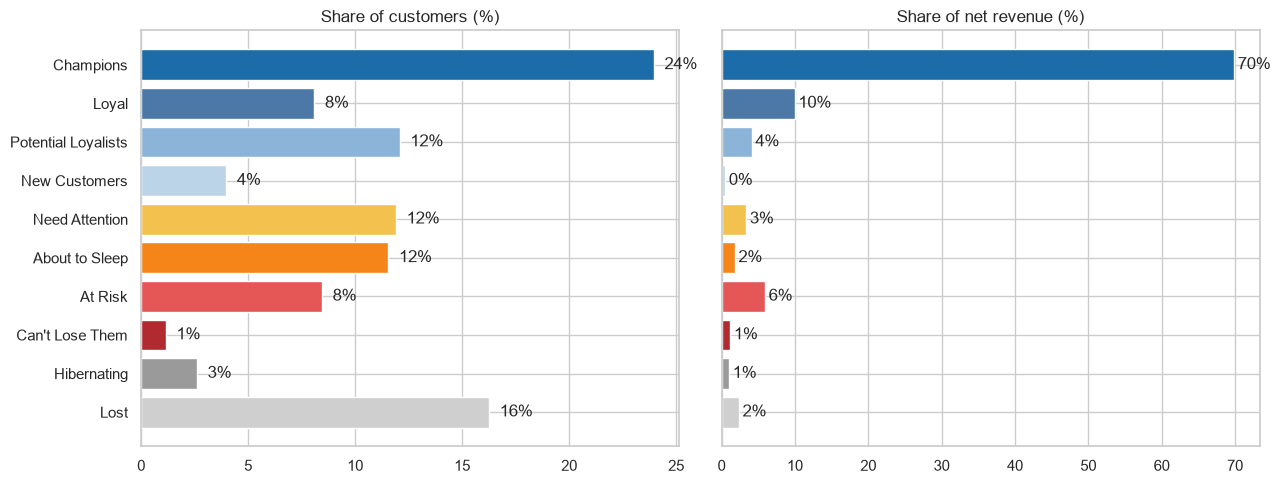

In [7]:
colors = {
    "Champions": "#1b6ca8", "Loyal": "#4C78A8", "Potential Loyalists": "#8cb4d9", "New Customers": "#bcd4e8",
    "Need Attention": "#f2c14e", "About to Sleep": "#f58518", "At Risk": "#e45756",
    "Can't Lose Them": "#b02a30", "Hibernating": "#9a9a9a", "Lost": "#cfcfcf",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
y = np.arange(len(ORDER))
axes[0].barh(y, segments.customer_share * 100, color=[colors[s] for s in ORDER])
axes[0].set_title("Share of customers (%)")
axes[1].barh(y, segments.revenue_share * 100, color=[colors[s] for s in ORDER])
axes[1].set_title("Share of net revenue (%)")
axes[0].set_yticks(y, ORDER)
axes[0].invert_yaxis()
for ax, col in zip(axes, ("customer_share", "revenue_share")):
    for yi, v in zip(y, segments[col] * 100):
        ax.text(v + 0.5, yi, f"{v:.0f}%", va="center")
save(fig, "04_rfm_segments")
plt.show()

## 5. Who is slipping away?

In [8]:
slipping = ["At Risk", "Can't Lose Them", "About to Sleep", "Need Attention"]
sl = segments.loc[slipping]
print(f"Slipping segments hold {sl.customers.sum():,} customers ({sl.customer_share.sum():.0%}) and £{sl.revenue.sum():,.0f} ({sl.revenue_share.sum():.0%}) of net revenue to date")

# The most valuable customers who have gone quiet (>2x the typical 71-day upper gap = 142 days)
quiet_vips = rfm[(rfm.M == 5) & (rfm.recency > 142)].sort_values("monetary", ascending=False)
print(f"Top-quintile-value customers silent > 142 days: {len(quiet_vips):,}, lifetime net sales £{quiet_vips.monetary.sum():,.0f}")
quiet_vips.head(10)[["recency", "frequency", "monetary", "segment"]]

Slipping segments hold 1,929 customers (33%) and £2,002,517 (12%) of net revenue to date
Top-quintile-value customers silent > 142 days: 126, lifetime net sales £858,186


,recency,frequency,monetary,segment
customer_id,,,,
16754,372,29.00,"54,558.18",At Risk
13093,275,55.00,"53,274.33",At Risk
17850,372,155.00,"50,407.77",At Risk
13902,632,5.00,"30,411.26",Can't Lose Them
12482,576,29.00,"21,893.53",Can't Lose Them
15749,235,3.00,"21,535.90",At Risk
15808,306,21.00,"17,038.95",At Risk
16553,163,33.00,"16,500.12",Loyal
12980,157,21.00,"15,909.39",Loyal


## 6. Key takeaways

| Finding | Evidence |
|---|---|
| A quarter of customers generate most of the revenue | **Champions: 24% of customers, 70% of net revenue** (£11.4M). They average 16 orders and last bought 19 days ago |
| Loyal customers add another 10% | 8% of customers, £1.6M |
| One third of customers are slipping | Need Attention, About to Sleep, At Risk and Can't Lose Them = 1,929 customers (33%) and £2.0M (12%) of revenue to date |
| High-value customers have gone quiet | 126 customers in the top value quintile have been silent for 142+ days, with £858k lifetime net sales |
| Many one-time buyers never return | Lost + About to Sleep = 1,623 customers (28%) averaging 1.3 orders and about £400 each, with only 4% of revenue |

### How to read this
- Revenue figures are **lifetime net sales within the 2-year window**, not forecasts. They show what these groups were worth, not what is recoverable.
- "At Risk" means silent for 6-13 months. Given a median reorder gap of 32 days, many of them have probably already churned. Notebook 05 checks how many actually come back.
- Frequency uses fixed order-count bands (1, 2, 3-4, 5-9, 10+) because quintiles split identical one-order customers arbitrarily. Recency and monetary use quintiles.
- 41 customers with net value <= 0 (everything cancelled) are excluded.

### 5 Whys #2
Confirmed: revenue depends on a small group of loyal wholesale buyers. The retention priority is protecting Champions and winning back the few high-value customers who have gone quiet, not the long tail of one-time buyers.

## 7. Save outputs

In [9]:
rfm.reset_index().to_csv(PROCESSED_DIR / "rfm_customers.csv", index=False)
segments.reset_index().to_csv(PROCESSED_DIR / "rfm_segments.csv", index=False)
print(f"saved {len(rfm):,} customers and {len(segments)} segments")

saved 5,837 customers and 10 segments
